In [2]:
import json
import gzip
import pandas as pd

In [3]:
with gzip.open("../../data/meta_Electronics.jsonl.gz", "rt") as f:
    first_line = json.loads(f.readline())
first_line

{'main_category': 'All Electronics',
 'title': 'FS-1051 FATSHARK TELEPORTER V3 HEADSET',
 'average_rating': 3.5,
 'rating_number': 6,
 'features': [],
 'description': ['Teleporter V3 The “Teleporter V3” kit sets a new level of value in the FPV world with Fat Shark renowned performance and quality. The fun of FPV is experienced firsthand through the large screen FPV headset with integrated NexwaveRF receiver technology while simultaneously recording onboard HD footage with the included “PilotHD” camera. The “Teleporter V3” kit comes complete with everything you need to step into the cockpit of your FPV vehicle. We’ve included our powerful 250mW 5.8Ghz transmitter, 25 degree FOV headset (largest QVGA display available), the brand new “PilotHD” camera with live AV out and all the cables, antennas and connectors needed.'],
 'price': None,
 'images': [{'thumb': 'https://m.media-amazon.com/images/I/41qrX56lsYL._AC_US40_.jpg',
   'large': 'https://m.media-amazon.com/images/I/41qrX56lsYL._AC_.

In [4]:
def filter_data_by_date(data: dict) -> bool:
    return int(data["details"]["Date First Available"][-4:]) < 2022

In [7]:
with gzip.open("../../data/meta_Electronics.jsonl.gz", "rt") as fp, \
     open("../../data/meta_Electronics_2022_2023.jsonl", "w", encoding="utf-8") as fp_out, \
     open("../../data/meta_Electronics_2022_2023_no_date.jsonl", "w", encoding="utf-8") as fp_out_no_date:
    for i, line in enumerate(fp, start=1):
        data = json.loads(line)
        try:
            if not filter_data_by_date(data):
                fp_out.write(json.dumps(data) + "\n")
        except (KeyError, ValueError):
            fp_out_no_date.write(json.dumps(data) + "\n")
        if i % 100000 == 0:
            print(f"Processed {i} lines")

Processed 100000 lines
Processed 200000 lines
Processed 300000 lines
Processed 400000 lines
Processed 500000 lines
Processed 600000 lines
Processed 700000 lines
Processed 800000 lines
Processed 900000 lines
Processed 1000000 lines
Processed 1100000 lines
Processed 1200000 lines
Processed 1300000 lines
Processed 1400000 lines
Processed 1500000 lines
Processed 1600000 lines


In [8]:
with open("../../data/meta_Electronics_2022_2023.jsonl", "r") as fp, \
     open("../../data/meta_Electronics_2022_2023_with_category.jsonl", "w", encoding="utf-8") as fp_out, \
     open("../../data/meta_Electronics_2022_2023_no_category.jsonl", "w", encoding="utf-8") as fp_out_no_category:
    for line in fp:
        data = json.loads(line)
        if data["main_category"] is not None:
            fp_out.write(json.dumps(data) + "\n")
        else:
            fp_out_no_category.write(json.dumps(data) + "\n")

103993


Matplotlib is building the font cache; this may take a moment.


<Axes: xlabel='main_category'>

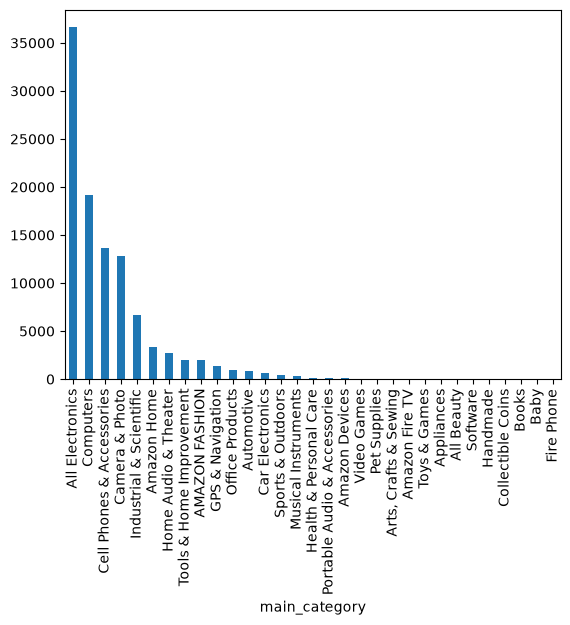

In [9]:
df = pd.read_json("../../data/meta_Electronics_2022_2023_with_category.jsonl", lines=True)
print(len(df))
df["main_category"].value_counts().plot(kind="bar")

17290


<Axes: ylabel='Frequency'>

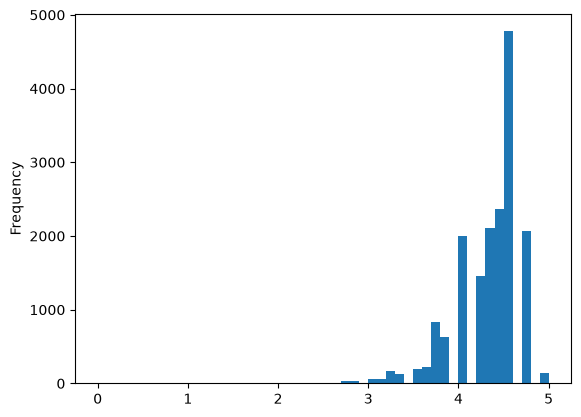

In [10]:
df_ratings_100 = df[df["rating_number"] >= 100]
print(len(df_ratings_100))
df_ratings_100["average_rating"].plot(kind="hist", bins=50, range=(0, 5))

<Axes: ylabel='Frequency'>

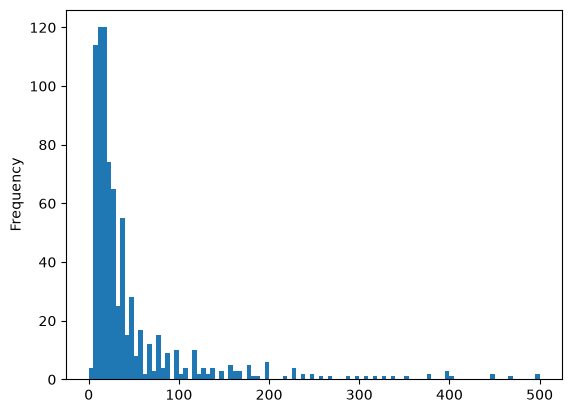

In [11]:
df_sample_1000 = df_ratings_100.sample(n=1000, random_state=42)
df_sample_1000["price"].plot(kind="hist", bins=100, range=(0, 500))

In [12]:
df_sample_1000.to_json(
    "../../data/meta_Electronics_2022_2023_with_category_ratings_100_sample_1000.jsonl",
    orient="records",
    lines=True,
)

In [13]:
df_test = pd.read_json("../../data/meta_Electronics_2022_2023_with_category_ratings_100_sample_1000.jsonl", lines=True)
len(df_test)

1000